Project 4

DATA VISUALIZATION

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [47]:
df = pd.read_csv("cleaned_orders.csv")
df["Date"] = pd.to_datetime(df["Date"])
sns.set_theme(style="whitegrid")

Bar chart:Top 10 products by total sales


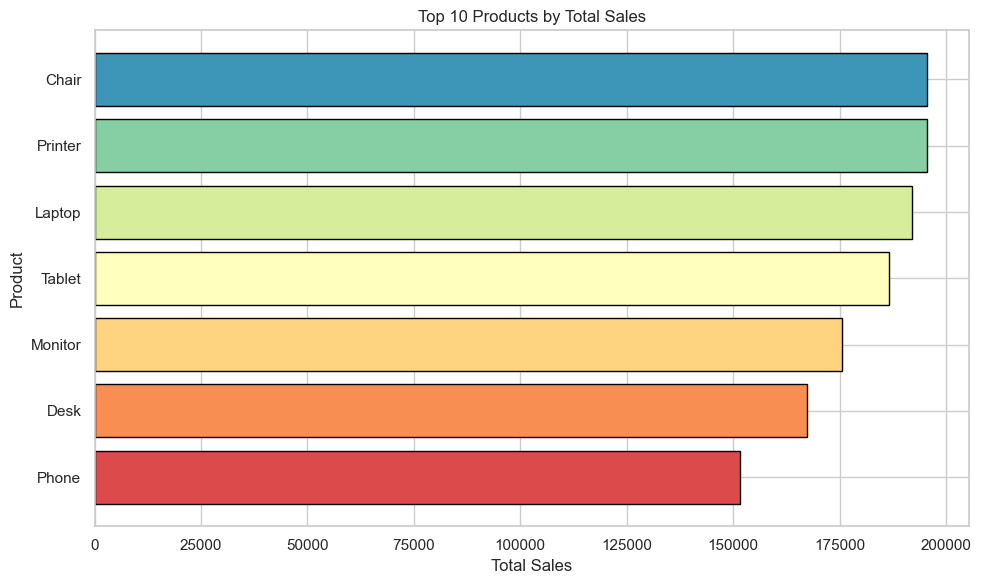

In [48]:
product_revenue = (
    df.groupby("Product")["TotalPrice"]
    .sum()
    .nlargest(10)
    .sort_values()
)

colors = sns.color_palette("Spectral", len(product_revenue))

plt.figure(figsize=(10, 6))
plt.barh(
    product_revenue.index,
    product_revenue.values,
    color=colors,
    edgecolor="black"
)

plt.title("Top 10 Products by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

Area chart: Monthly sales trend

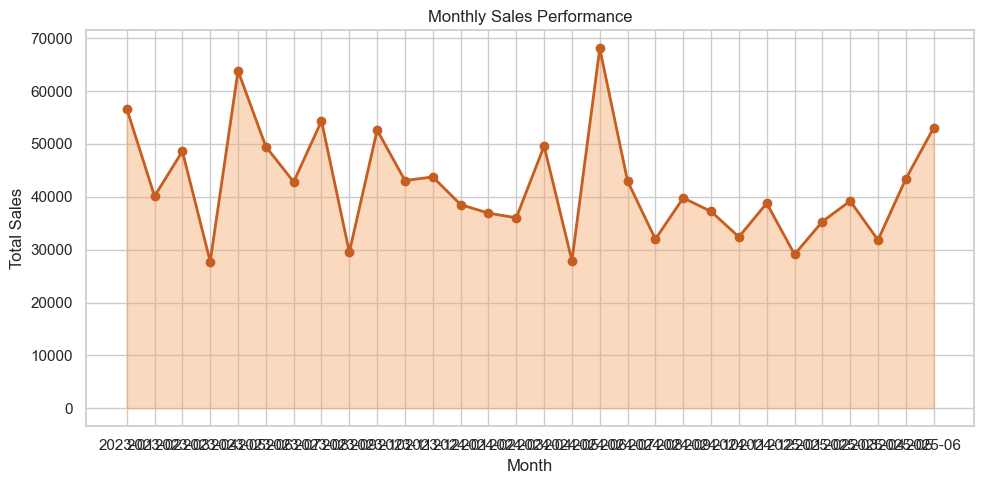

In [49]:
df["Month"] = df["Date"].dt.to_period("M")

monthly_sales = df.groupby("Month")["TotalPrice"].sum()
monthly_sales.index = monthly_sales.index.astype(str)

plt.figure(figsize=(10, 5))

plt.fill_between(
    range(len(monthly_sales)),
    monthly_sales.values,
    color="#F4A261",
    alpha=0.4
)

plt.plot(
    range(len(monthly_sales)),
    monthly_sales.values,
    color="#C65D21",
    marker="o",
    linewidth=2
)

plt.title("Monthly Sales Performance")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(range(len(monthly_sales)), monthly_sales.index, rotation=0)
plt.tight_layout()
plt.show()

Donut chart: Customer payment preferences

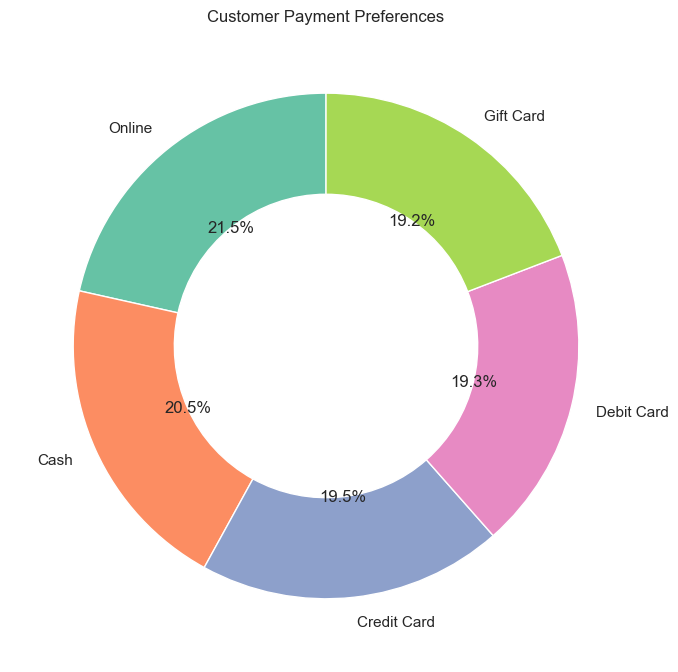

In [50]:
payment_counts = df["PaymentMethod"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    payment_counts.values,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=sns.color_palette("Set2", len(payment_counts)),
    wedgeprops={"width": 0.4, "edgecolor": "white"}
)

plt.title("Customer Payment Preferences")
plt.tight_layout()
plt.show()

Horizontal bar chart: Sales by referral source

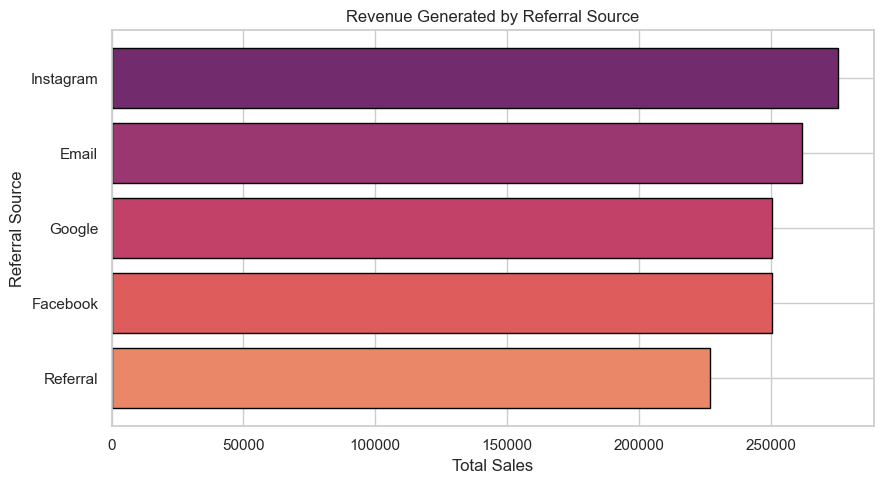

In [51]:
referral_sales = (
    df.groupby("ReferralSource")["TotalPrice"]
    .sum()
    .sort_values()
)

plt.figure(figsize=(9, 5))

plt.barh(
    referral_sales.index,
    referral_sales.values,
    color=sns.color_palette("flare", len(referral_sales)),
    edgecolor="black"
)

plt.title("Revenue Generated by Referral Source")
plt.xlabel("Total Sales")
plt.ylabel("Referral Source")
plt.tight_layout()
plt.show()


Display business insights

In [53]:
print("PROJECT 4: BUSINESS INSIGHTS")
print("-" * 35)

print("Total Orders:", len(df))
print("Unique Customers:", df["CustomerID"].nunique())
print("Total Sales:", round(df["TotalPrice"].sum(), 2))
print("Average Order Value:", round(df["TotalPrice"].mean(), 2))

print(
    "Highest Revenue Product:",
    df.groupby("Product")["TotalPrice"].sum().idxmax()
)

print(
    "Highest Spending Customer:",
    df.groupby("CustomerID")["TotalPrice"].sum().idxmax()
)

print(
    "Best Performing Referral Source:",
    df.groupby("ReferralSource")["TotalPrice"].sum().idxmax()
)


PROJECT 4: BUSINESS INSIGHTS
-----------------------------------
Total Orders: 1200
Unique Customers: 1189
Total Sales: 1264761.96
Average Order Value: 1053.97
Highest Revenue Product: Chair
Highest Spending Customer: C38840
Best Performing Referral Source: Instagram
